In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from google.colab import drive

# Membaca dataset utama
drive.mount('/content/drive')

Mounted at /content/drive
Mounted at /content/drive


In [3]:
df = pd.read_csv('/content/drive/MyDrive/SEMESTER 5/DATA SCIENCE/sesi6/nasabah_raw.csv')

a. Pemeriksaan Awal & Penghapusan Duplikat

In [4]:
# 1. Cek dimensi awal (baris, kolom) & tipe data
print("Dimensi awal:", df.shape)
print("\nInformasi Dataset:")
df.info()

# 2. Identifikasi dan tampilkan sampel data duplikat penuh
jumlah_duplikat = df.duplicated().sum()
print(f"\nJumlah baris duplikat penuh: {jumlah_duplikat}")

if jumlah_duplikat > 0:
    print("Sampel data duplikat:")
    display(df[df.duplicated(keep=False)].head())

# Hapus seluruh duplikat
df = df.drop_duplicates().reset_index(drop=True)

# 3. Cek sisa baris data
print(f"Sisa baris data setelah penghapusan duplikat: {df.shape[0]} baris")

Dimensi awal: (1045, 9)

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1045 entries, 0 to 1044
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_Pelanggan            1045 non-null   object 
 1   Usia                    1045 non-null   float64
 2   Pendapatan_Bulanan      983 non-null    float64
 3   Skor_Kredit             1045 non-null   float64
 4   Lama_Bekerja_Thn        1003 non-null   float64
 5   Status_Pernikahan       1045 non-null   object 
 6   Tingkat_Pendidikan      1008 non-null   object 
 7   Status_Default          1045 non-null   int64  
 8   Pendapatan_Tahunan_Est  983 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 73.6+ KB

Jumlah baris duplikat penuh: 45
Sampel data duplikat:


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est
59,CUST-1060,53.0,14765000.0,461.0,3.0,Single,SMA,0,177180000.0
76,CUST-1077,34.0,6920000.0,510.0,22.0,Single,SMA,1,83040000.0
96,CUST-1097,27.0,12499000.0,578.0,4.0,Single,Sarjana,0,149988000.0
101,CUST-1102,43.0,7972000.0,365.0,6.0,Single,Magister,1,95664000.0
136,CUST-1137,-5.0,NaN,580.0,11.0,Cerai,Sarjana,1,NaN


Sisa baris data setelah penghapusan duplikat: 1000 baris


penjelasan konsep:
1. Dimensi Awal & Kualitas Data: Dataset nasabah_raw.csv awalnya memiliki dimensi 1.045 baris dan 9 kolom.
2. ditemukan anomali awal pada sampel data (seperti CUST-1137 yang memiliki usia -5.0) yang akan ditangani pada tahap pembersihan.
3. Ditemukan sebanyak 45 baris duplikat penuh. dan melakukan penghapusan pada data duplikat tersebut.
4. Setelah seluruh baris duplikat dihapus menggunakan drop_duplicates(), sisa data bersih yang unik berjumlah 1.000 baris (1045 - 45 = 1000).

b. Penanganan Kesalahan Data

In [5]:
# 1. Cek dan bersihkan format teks pada Status_Pernikahan
print("Sebelum dibersihkan:", df['Status_Pernikahan'].unique())

# Hilangkan spasi berlebih di awal/akhir (.strip) dan seragamkan huruf kapital (.title)
df['Status_Pernikahan'] = df['Status_Pernikahan'].astype(str).str.strip().str.title()
# Kembalikan string 'Nan' (jika ada) menjadi nilai kosong asli (np.nan)
df['Status_Pernikahan'] = df['Status_Pernikahan'].replace('Nan', np.nan)

print("Sesudah dibersihkan:", df['Status_Pernikahan'].unique())

# 2. Pemeriksaan logis pada kolom Usia (17 - 100 tahun)
usia_invalid = df[(df['Usia'] < 17) | (df['Usia'] > 100)]
print(f"\nJumlah data usia tidak valid: {len(usia_invalid)}")

# Ubah nilai di luar batas 17-100 menjadi NaN
df.loc[(df['Usia'] < 17) | (df['Usia'] > 100), 'Usia'] = np.nan

Sebelum dibersihkan: ['Menikah' 'Single' 'single' 'Cerai' ' MENIKAH ']
Sesudah dibersihkan: ['Menikah' 'Single' 'Cerai']

Jumlah data usia tidak valid: 35


ANALISIS :
Koreksi kesalahan nilai pada Usia wajib dilakukan sebelum menghitung mean atau median karena nilai yang tidak logis (misalnya usia -5 atau 999 tahun) adalah noise yang akan menarik nilai mean secara ekstrem dan menggeser nilai median. Jika kita langsung melakukan imputasi sebelum nilai aneh itu diubah menjadi NaN, angka yang salah tersebut justru ikut dipakai untuk mengisi data yang kosong.

c. Integrasi Data

In [6]:
# Membaca dataset eksternal
df_eksternal = pd.read_csv('/content/drive/MyDrive/SEMESTER 5/DATA SCIENCE/sesi6/data_kredit_eksternal.csv')

# 1 & 2. Menggabungkan data dengan metode Left Join berdasarkan ID_Pelanggan
df_merged = pd.merge(df, df_eksternal, on='ID_Pelanggan', how='left')

# 3. Tampilkan dimensi dataset setelah penggabungan
print("Dimensi setelah left join:", df_merged.shape)

Dimensi setelah left join: (1000, 11)


penjelasan konsep:
Metode how='left' memastikan seluruh baris nasabah di tabel utama (df) tetap dipertahankan. Jika ada nasabah yang datanya belum tercatat di data_kredit_eksternal.csv, barisnya tidak akan hilang, melainkan kolom tambahannya akan otomatis terisi NaN

d. Penanganan Data yang Hilang (Missing Values)

In [7]:
# 1. Tampilkan persentase missing values tiap kolom
persentase_missing = (df_merged.isnull().sum() / len(df_merged)) * 100
print("Persentase Missing Values (%):\n", persentase_missing)

# 2a. Numerik kontinu -> isi dengan Median
kolom_kontinu = ['Usia', 'Pendapatan_Bulanan', 'Lama_Bekerja_Thn', 'Pendapatan_Tahunan_Est']
for col in kolom_kontinu:
    df_merged[col] = df_merged[col].fillna(df_merged[col].median())

# 2b. Diskrit -> isi dengan 0 (asumsi tidak punya kartu kredit)
df_merged['Jumlah_Kartu_Kredit'] = df_merged['Jumlah_Kartu_Kredit'].fillna(0)

# 2c. Kategorikal -> isi dengan Modus (.mode()[0])
kolom_kategorikal = ['Tingkat_Pendidikan', 'Pernah_Gagal_Bayar_Lain']
for col in kolom_kategorikal:
    df_merged[col] = df_merged[col].fillna(df_merged[col].mode()[0])

# (Tambahan pengaman jika Status_Pernikahan juga memiliki NaN)
if df_merged['Status_Pernikahan'].isnull().sum() > 0:
    df_merged['Status_Pernikahan'] = df_merged['Status_Pernikahan'].fillna(df_merged['Status_Pernikahan'].mode()[0])

# 3. Pastikan sudah 0 missing value
print("\nTotal missing values tersisa:", df_merged.isnull().sum().sum())

Persentase Missing Values (%):
 ID_Pelanggan                0.0
Usia                        3.5
Pendapatan_Bulanan          6.0
Skor_Kredit                 0.0
Lama_Bekerja_Thn            4.0
Status_Pernikahan           0.0
Tingkat_Pendidikan          3.5
Status_Default              0.0
Pendapatan_Tahunan_Est      6.0
Pernah_Gagal_Bayar_Lain    15.0
Jumlah_Kartu_Kredit        15.0
dtype: float64

Total missing values tersisa: 0


penjelasan konsep:
1. Algoritma Machine Learning umumnya akan error jika masih ada nilai NaN, jadi kita isi sesuai karakter masing-masing kolom.
2. Numerik Kontinu (Usia, Pendapatan_Bulanan, Lama_Bekerja_Thn, Pendapatan_Tahunan_Est): Diisi menggunakan nilai median karena lebih tahan terhadap pengaruh nilai ekstrem (outlier) dibandingkan nilai rata-rata (mean).
3. Numerik Diskrit (Jumlah_Kartu_Kredit): Diisi dengan angka 0, dengan asumsi logis bahwa nasabah yang tidak tercatat pada data kredit eksternal memang belum memiliki kartu kredit.
4. Kategorikal (Tingkat_Pendidikan, Pernah_Gagal_Bayar_Lain): Diisi menggunakan modus (nilai yang paling sering muncul) karena data berbentuk kategori teks tidak dapat dihitung nilai tengahnya.

e. Penanganan Pencilan (Outlier Handling)

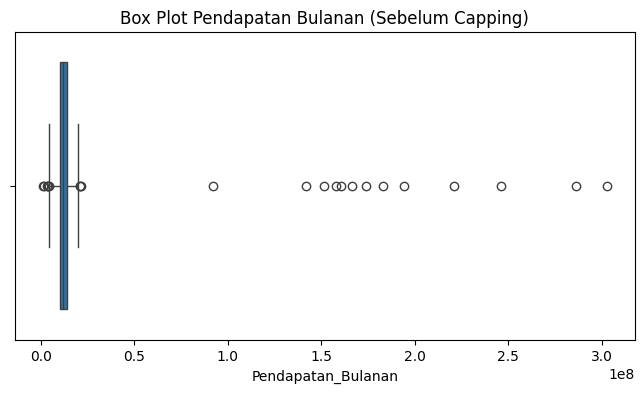

Batas Bawah: 4,329,625.00 | Batas Atas: 19,962,625.00


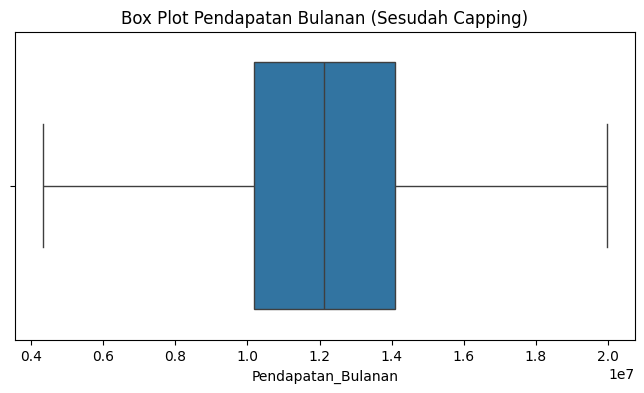

In [8]:
# 1. Visualisasi Box Plot sebelum penanganan outlier
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_merged['Pendapatan_Bulanan'])
plt.title('Box Plot Pendapatan Bulanan (Sebelum Capping)')
plt.show()

# 2. Hitung Q1, Q3, IQR, Batas Bawah, dan Batas Atas
Q1 = df_merged['Pendapatan_Bulanan'].quantile(0.25)
Q3 = df_merged['Pendapatan_Bulanan'].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR
print(f"Batas Bawah: {batas_bawah:,.2f} | Batas Atas: {batas_atas:,.2f}")

# 3. Terapkan Capping (pembatasan nilai ekstrem tanpa membuang baris)
df_merged['Pendapatan_Bulanan'] = np.clip(df_merged['Pendapatan_Bulanan'], batas_bawah, batas_atas)

# Visualisasi ulang untuk memastikan outlier sudah tertangani
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_merged['Pendapatan_Bulanan'])
plt.title('Box Plot Pendapatan Bulanan (Sesudah Capping)')
plt.show()

ANALISIS:
1. Hasil Deteksi & Capping: Berdasarkan perhitungan IQR pada fitur Pendapatan_Bulanan, diperoleh batas bawah sebesar 4.329.625 dan batas atas sebesar 19.962.625. Nilai ekstrem di luar rentang tersebut telah dibatasi (capping) menggunakan np.clip(), sehingga pada box plot kedua tidak lagi terlihat titik outlier.
2. Konsekuensi Negatif Jika Menghapus Baris (Drop Rows):
a. Hilangnya Informasi & Berkurangnya Ukuran Sampel: Data nasabah yang memiliki pendapatan sangat tinggi tetap merupakan fakta valid di dunia perbankan. Menghapusnya akan mengurangi jumlah data latih secara percuma.
b. Mengganggu Proporsi Kelas Target (Status_Default): Pada kasus kredit, jumlah nasabah yang gagal bayar biasanya jauh lebih sedikit dibanding yang lancar (imbalanced). Jika baris outlier dibuang, kita berisiko ikut membuang sampel nasabah gagal bayar yang sangat berharga untuk dipelajari oleh model.

f. Pengkodean Data Kategorikal (Categorical Encoding)

In [9]:
# 1. Ordinal Encoding pada Tingkat_Pendidikan
urutan_pendidikan = {'SMA': 1, 'Sarjana': 2, 'Magister': 3}
df_merged['Tingkat_Pendidikan_Encoded'] = df_merged['Tingkat_Pendidikan'].map(urutan_pendidikan)

# 2. Binary Mapping pada Pernah_Gagal_Bayar_Lain
# Catatan: Sesuaikan kunci mapping jika isi kolomnya berupa 'Ya'/'Tidak' atau 'Yes'/'No'
mapping_biner = {'Tidak': 0, 'Ya': 1, 'No': 0, 'Yes': 1}
df_merged['Pernah_Gagal_Bayar_Encoded'] = df_merged['Pernah_Gagal_Bayar_Lain'].map(mapping_biner)

# 3. One-Hot Encoding pada Status_Pernikahan dengan drop_first=True
df_encoded = pd.get_dummies(df_merged, columns=['Status_Pernikahan'], drop_first=True, dtype=int)

# 4. Hapus kolom teks asli dan ID_Pelanggan
kolom_dibuang = ['ID_Pelanggan', 'Tingkat_Pendidikan', 'Pernah_Gagal_Bayar_Lain']
df_encoded = df_encoded.drop(columns=kolom_dibuang)

print("Kolom setelah encoding:", df_encoded.columns.tolist())

Kolom setelah encoding: ['Usia', 'Pendapatan_Bulanan', 'Skor_Kredit', 'Lama_Bekerja_Thn', 'Status_Default', 'Pendapatan_Tahunan_Est', 'Jumlah_Kartu_Kredit', 'Tingkat_Pendidikan_Encoded', 'Pernah_Gagal_Bayar_Encoded', 'Status_Pernikahan_Menikah', 'Status_Pernikahan_Single']


Komputer hanya mengerti angka, sehingga teks kategori perlu diubah menjadi representasi numerik.

g. Penskalaan Fitur (Feature Scaling) & Simpan Hasil Akhir

In [10]:
# 1. Pisahkan fitur prediktor (X) dan target (y)
X = df_encoded.drop(columns=['Status_Default'])
y = df_encoded['Status_Default']

# Simpan ringkasan statistik 3 fitur numerik SEBELUM standarisasi
fitur_sampel = ['Usia', 'Pendapatan_Bulanan', 'Lama_Bekerja_Thn']
print("--- Statistik Sebelum Standarisasi ---")
display(X[fitur_sampel].describe().round(2))

# 2. Transformasi Standardization (Z-score) pada seluruh variabel prediktor
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns)

# 3. Tampilkan ringkasan statistik SESUDAH standarisasi
print("\n--- Statistik Sesudah Standarisasi ---")
display(X_scaled[fitur_sampel].describe().round(2))

# Gabungkan kembali X_scaled dan y untuk disimpan menjadi dataset final yang siap pakai
df_final = pd.concat([X_scaled, y.reset_index(drop=True)], axis=1)

# 4. Simpan ke file CSV sesuai instruksi
df_final.to_csv('clean_nasabah_final.csv', index=False)
print("\nBerhasil! File 'clean_nasabah_final.csv' telah disimpan.")

--- Statistik Sebelum Standarisasi ---


,Usia,Pendapatan_Bulanan,Lama_Bekerja_Thn
count,1000.00,1000.00,1000.00
mean,40.08,12127496.75,12.95
std,11.58,3062611.27,6.69
min,20.00,4329625.00,1.00
25%,30.00,10192000.00,8.00
50%,41.00,12132000.00,13.00
75%,50.00,14100250.00,19.00
max,59.00,19962625.00,24.00



--- Statistik Sesudah Standarisasi ---


,Usia,Pendapatan_Bulanan,Lama_Bekerja_Thn
count,1000.00,1000.00,1000.00
mean,-0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-1.74,-2.55,-1.79
25%,-0.87,-0.63,-0.74
50%,0.08,0.00,0.01
75%,0.86,0.64,0.91
max,1.63,2.56,1.65



Berhasil! File 'clean_nasabah_final.csv' telah disimpan.


penjelasan konsep:
1. Pemisahan Fitur (X) dan Target (y): Variabel target Status_Default dipisahkan terlebih dahulu agar nilai kategorinya (0 dan 1) tidak ikut berubah saat proses penskalaan berlangsung.
2. Tujuan Standardization (Z-score): Sebelum distandarisasi, fitur Pendapatan_Bulanan memiliki skala jutaan (mean sekitar 12.127.496), sedangkan Usia (mean 40,08) dan Lama_Bekerja_Thn (mean 12,95) hanya berskala puluhan. Perbedaan skala ekstrem ini dapat membuat fitur berangka besar mendominasi perhitungan algoritma Machine Learning.
3. Hasil Transformasi: Setelah diterapkan StandardScaler(), seluruh fitur prediktor kini memiliki skala yang setara dengan nilai rata-rata (mean) mendekati 0.00 dan standar deviasi (std) sebesar 1.00, sehingga dataset clean_nasabah_final.csv sudah siap digunakan untuk tahap pemodelan.